# Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("eCommerce-dataset.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null 

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


# Describe data

In [3]:
num_records = []
num_cols = df.select_dtypes(include="number").columns.tolist()
for col in num_cols:
    s = df[col].dropna()
    q1, median, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = ((s < lower_fence) | (s > upper_fence)).sum()

    num_records.append({
        "Feature": col,
        "Count": len(s),
        "Mean": s.mean(),
        "Median": median,
        "Std_Dev": s.std(),
        "IQR": iqr,
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": stats.skew(s),
        "Kurtosis": stats.kurtosis(s),
        "Zero_Pct (%)": (s == 0).mean() * 100,
        "IQR_Outliers": outliers,
        "Outlier_Pct (%)": (outliers / len(s)) * 100
    })

num_univariate_df = pd.DataFrame(num_records).set_index("Feature")
display(num_univariate_df.round(3))

,Count,Mean,Median,Std_Dev,IQR,Min,Max,Skewness,Kurtosis,Zero_Pct (%),IQR_Outliers,Outlier_Pct (%)
Feature,,,,,,,,,,,,
Age,47505,37.803,38.000,11.835,17.000,5.00,200.000,0.947,9.010,0.000,126,0.265
Membership_Years,50000,2.984,2.500,2.059,2.600,0.10,10.000,1.137,1.150,0.000,1581,3.162
Login_Frequency,50000,11.625,11.000,7.811,11.000,0.00,46.000,0.512,-0.144,8.060,309,0.618
Session_Duration_Avg,46601,27.661,26.800,10.871,15.000,1.00,75.600,0.401,-0.086,0.000,300,0.644
Pages_Per_Session,47000,8.738,8.400,3.778,5.200,1.00,24.100,0.391,-0.116,0.000,275,0.585
Cart_Abandonment_Rate,50000,57.080,58.100,16.283,22.300,0.00,143.743,-0.263,0.035,0.036,323,0.646
Wishlist_Items,46000,4.298,4.000,3.190,4.000,0.00,28.000,0.945,0.902,7.980,858,1.865
Total_Purchases,50000,13.112,12.000,7.017,9.000,-13.00,128.700,2.690,25.785,0.018,628,1.256
Average_Order_Value,50000,123.117,112.970,175.570,57.390,26.38,9666.379,42.363,1959.736,0.000,1005,2.010


# Handling Missing Values

In [4]:
df.isnull().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

# Correlation Heatmap

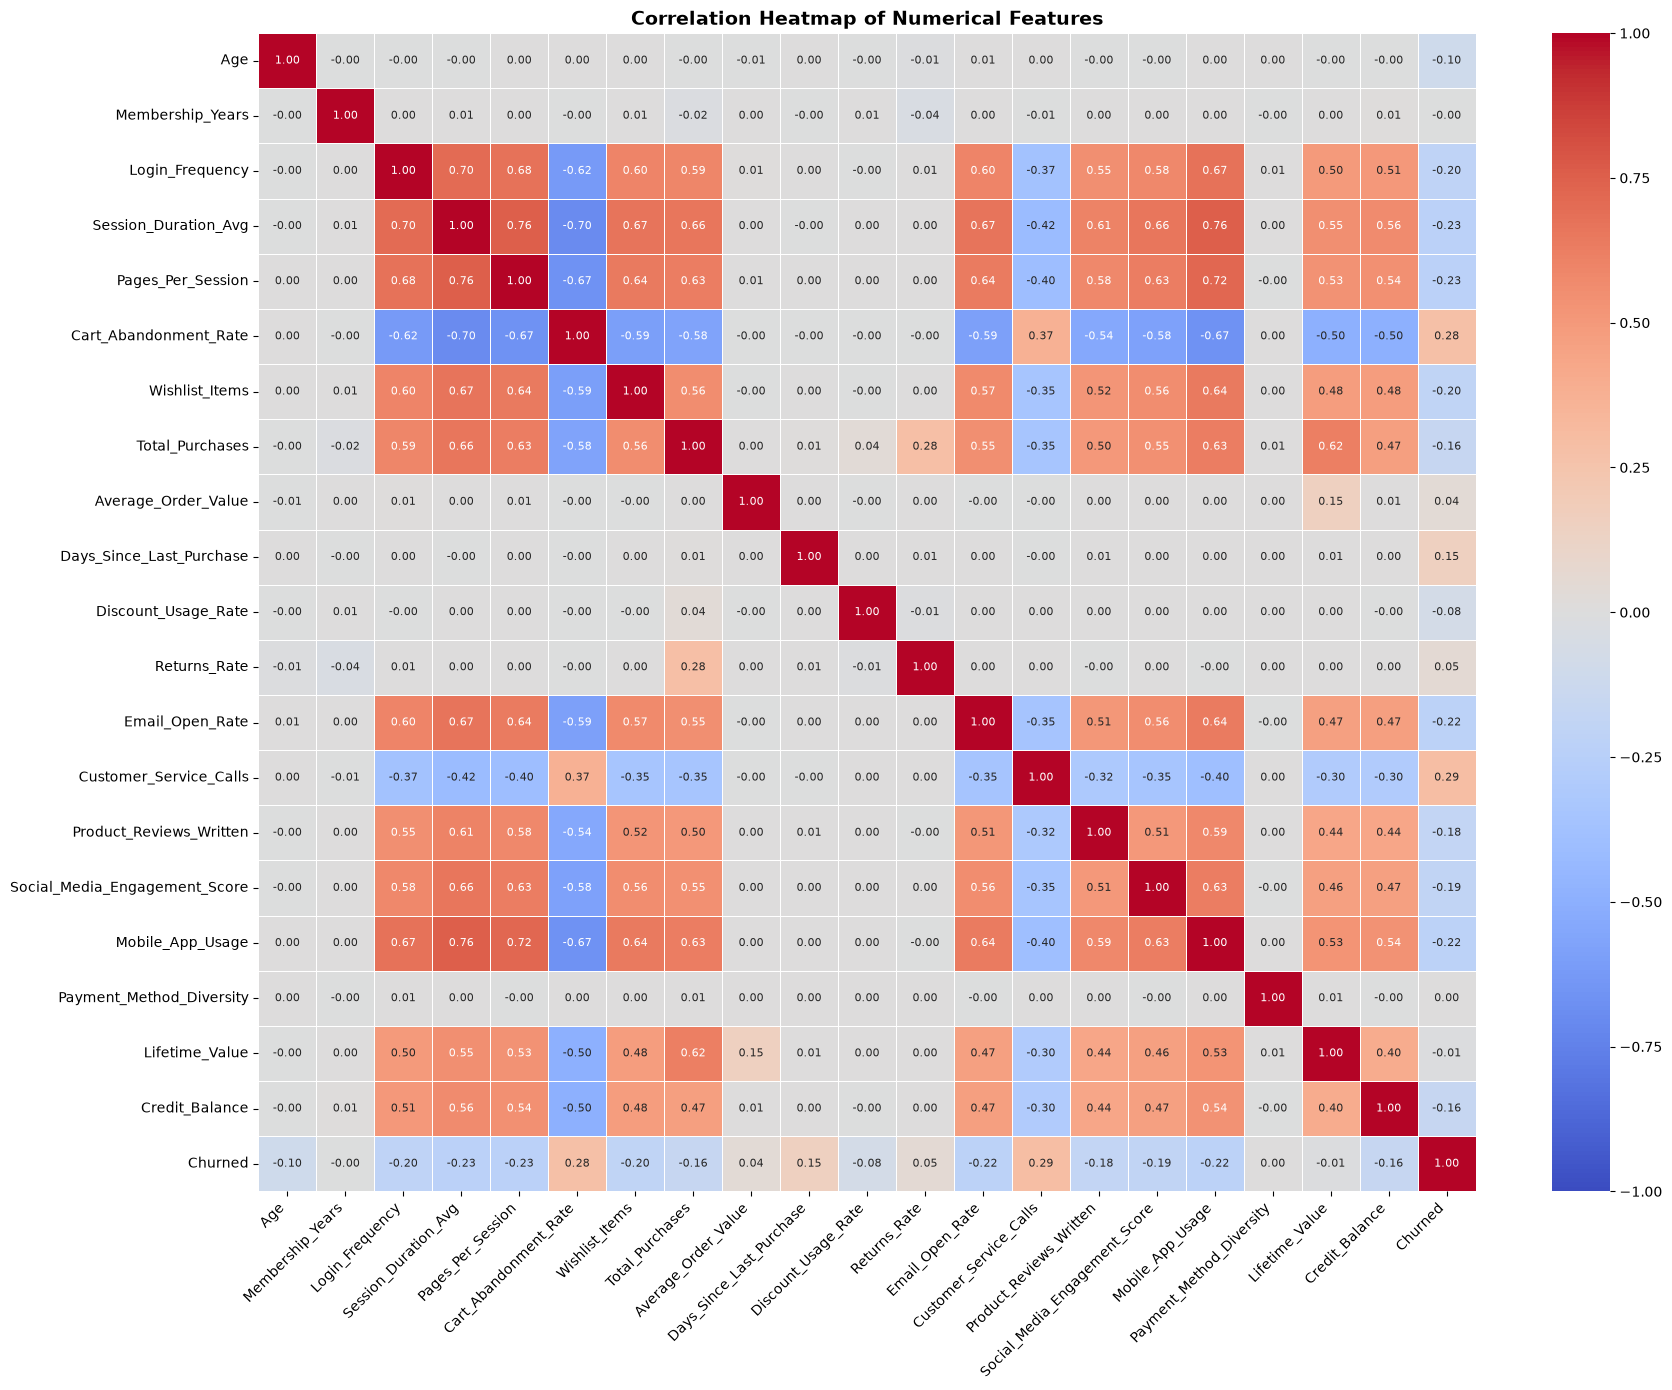

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization 3: Correlation Heatmap for Numerical Columns
plt.figure(figsize=(18, 14))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,              # Display correlation values in each cell
    fmt=".2f",               # Format labels to 2 decimal places
    annot_kws={"size": 8},   # Keep text readable without overlapping
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# Univariate Analysis

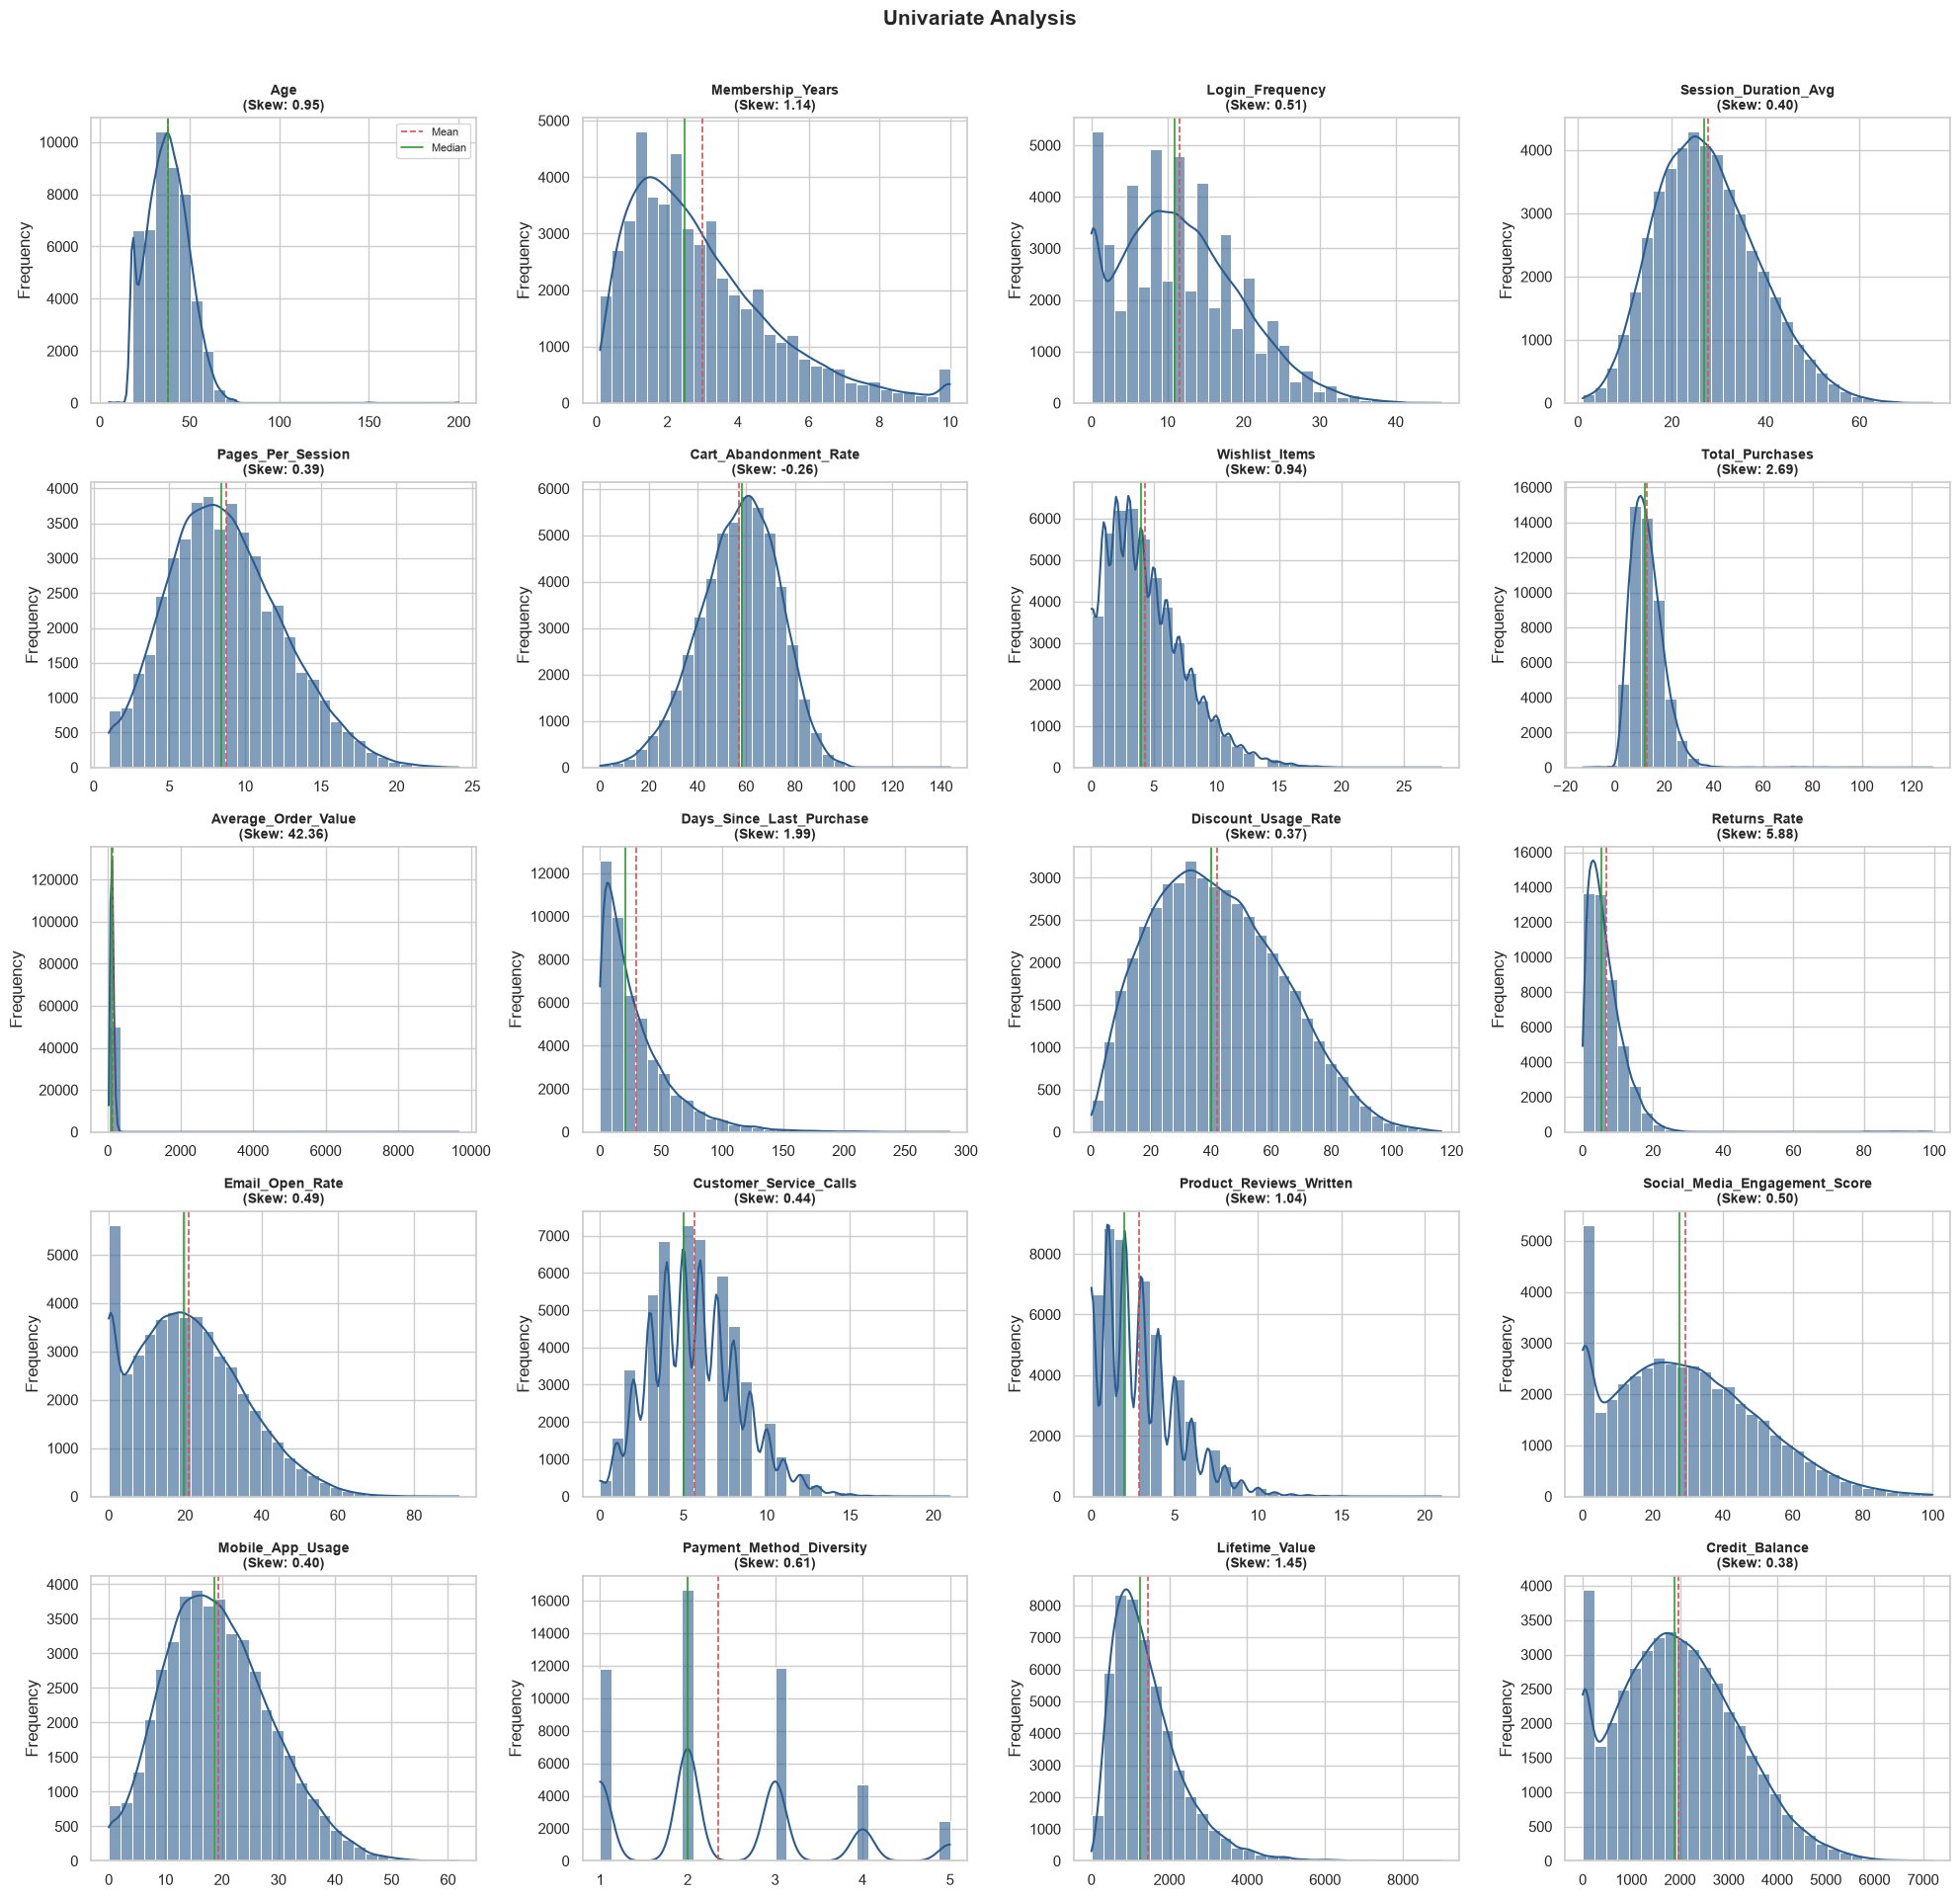

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.0)

TARGET_COL = "Churned"
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != TARGET_COL]
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()



n_cols_grid = 4
n_rows_grid = int(np.ceil(len(num_cols) / n_cols_grid))

fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(20, n_rows_grid * 3.8))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    s = df[col].dropna()
    skew_val = stats.skew(s)

    sns.histplot(s, bins=30, kde=True, color="#2b5c8f", alpha=0.6, ax=axes[idx])
    axes[idx].axvline(s.mean(), color="#d9534f", linestyle="--", linewidth=1.2, label="Mean")
    axes[idx].axvline(s.median(), color="#2ca02c", linestyle="-", linewidth=1.2, label="Median")
    axes[idx].set_title(f"{col}\n(Skew: {skew_val:.2f})", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("Frequency")
    if idx == 0:
        axes[idx].legend(fontsize=8)

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Univariate Analysis", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


# OUTLIER BOXPLOTS

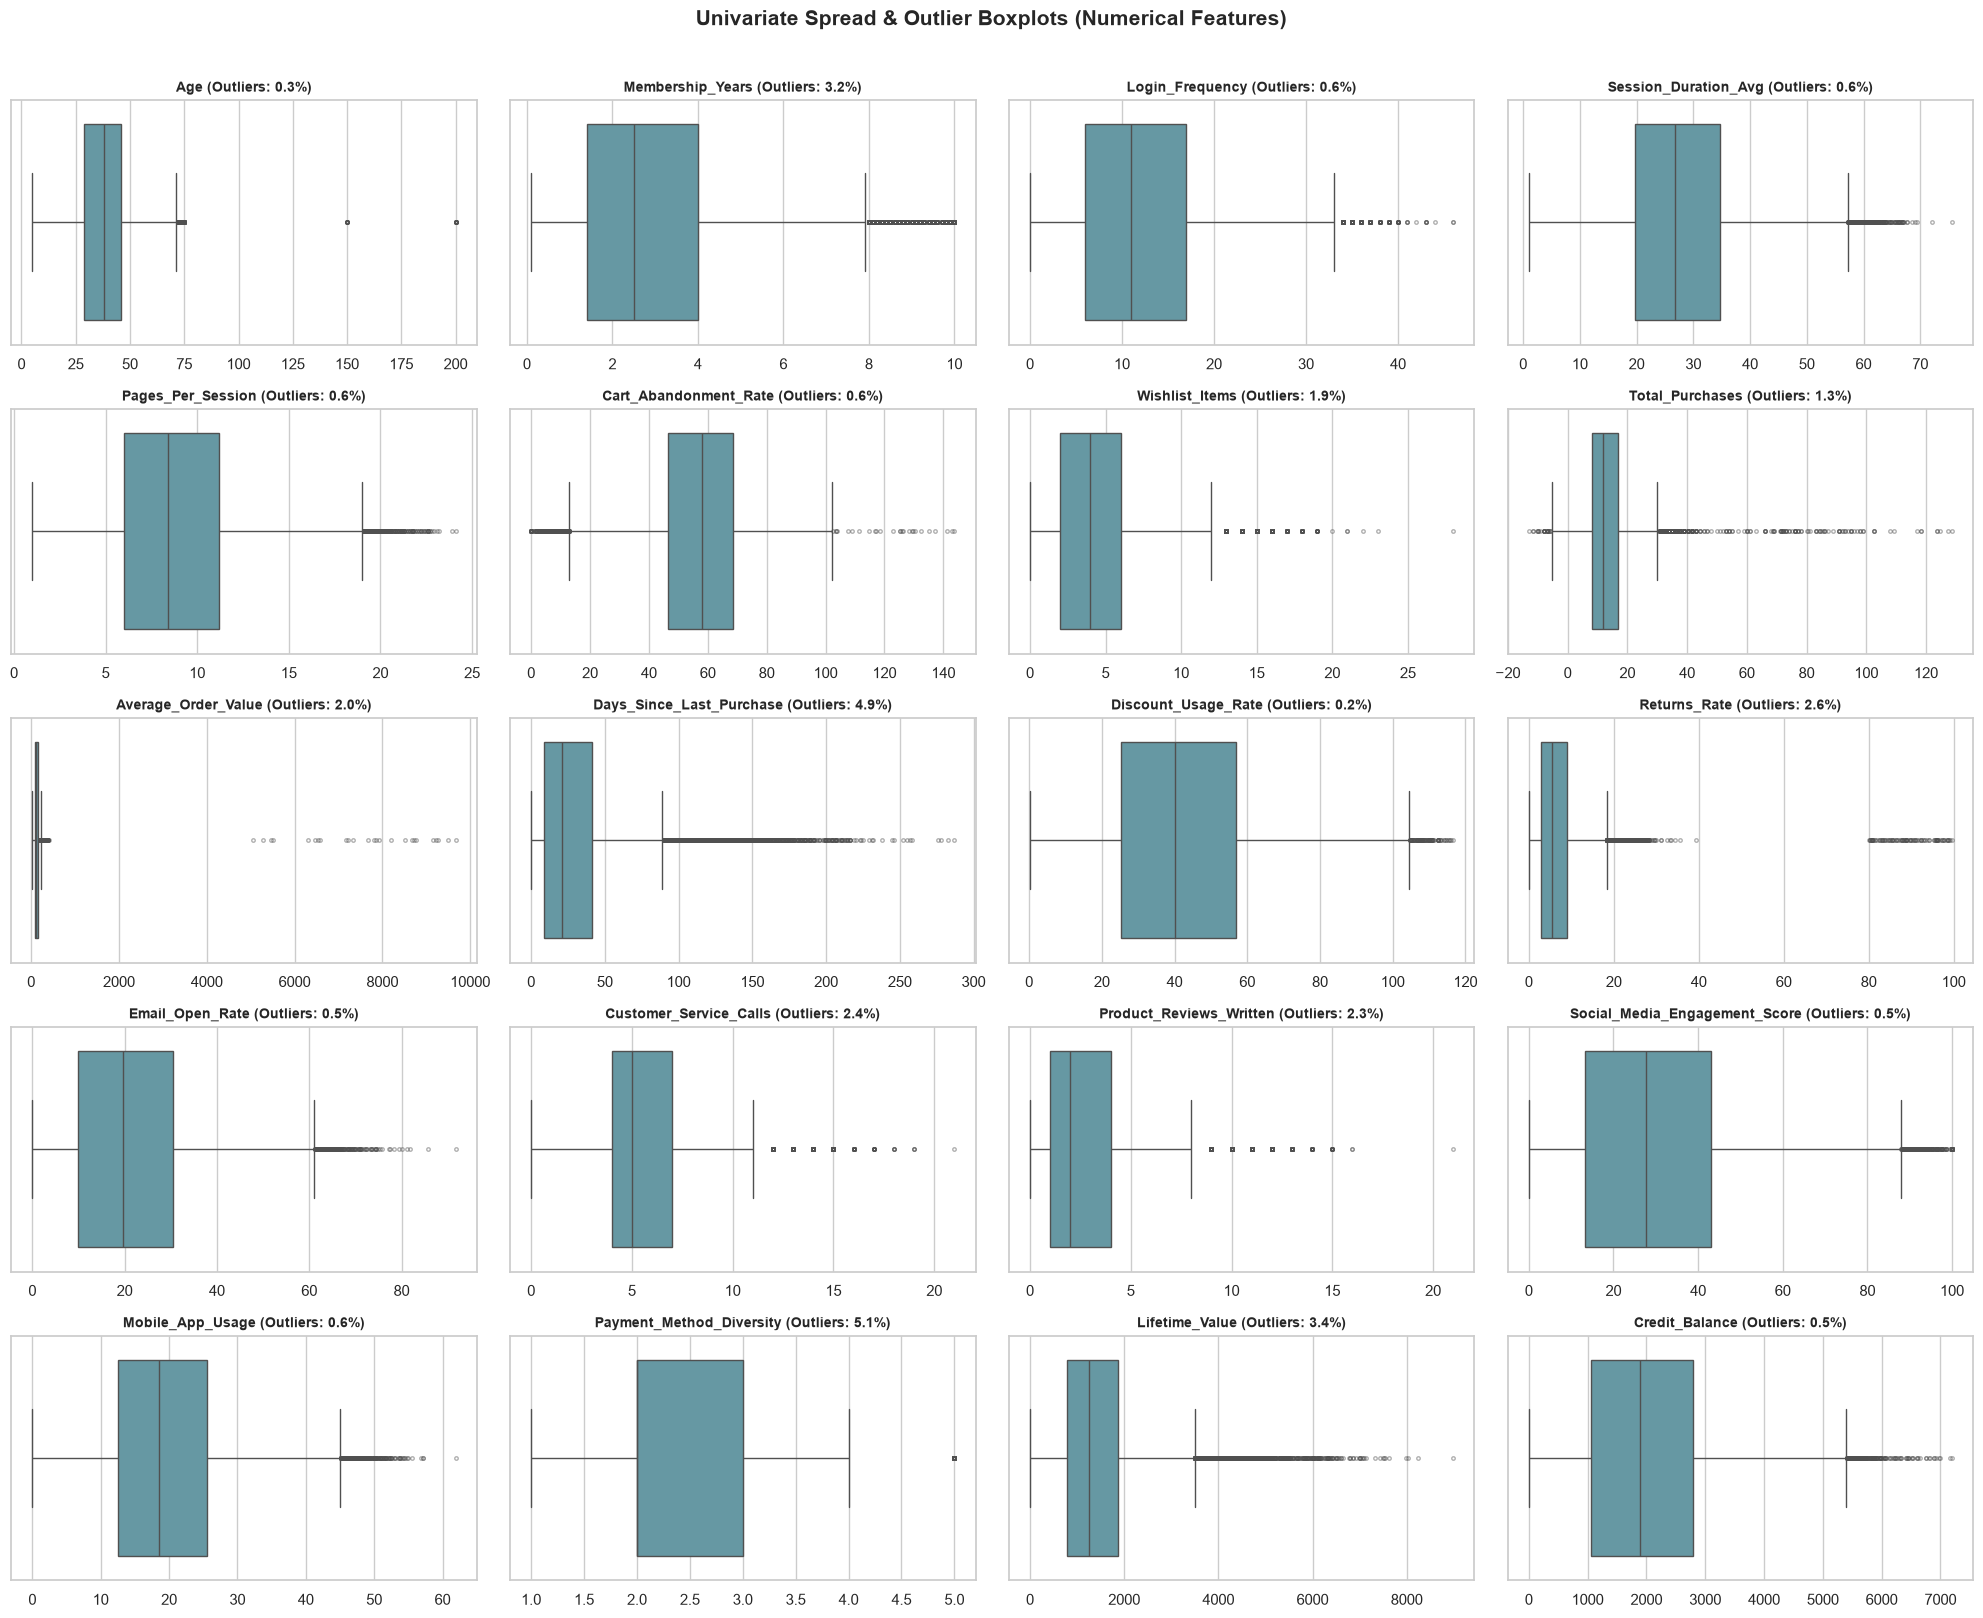

In [7]:
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(20, n_rows_grid * 3.2))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))).sum()
    out_pct = (outliers / len(s)) * 100

    sns.boxplot(
        x=df[col],
        color="#5c9ead",
        flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.45},
        ax=axes[idx]
    )
    axes[idx].set_title(f"{col} (Outliers: {out_pct:.1f}%)", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("")

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Univariate Spread & Outlier Boxplots (Numerical Features)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# CATEGORICAL BAR CHARTS

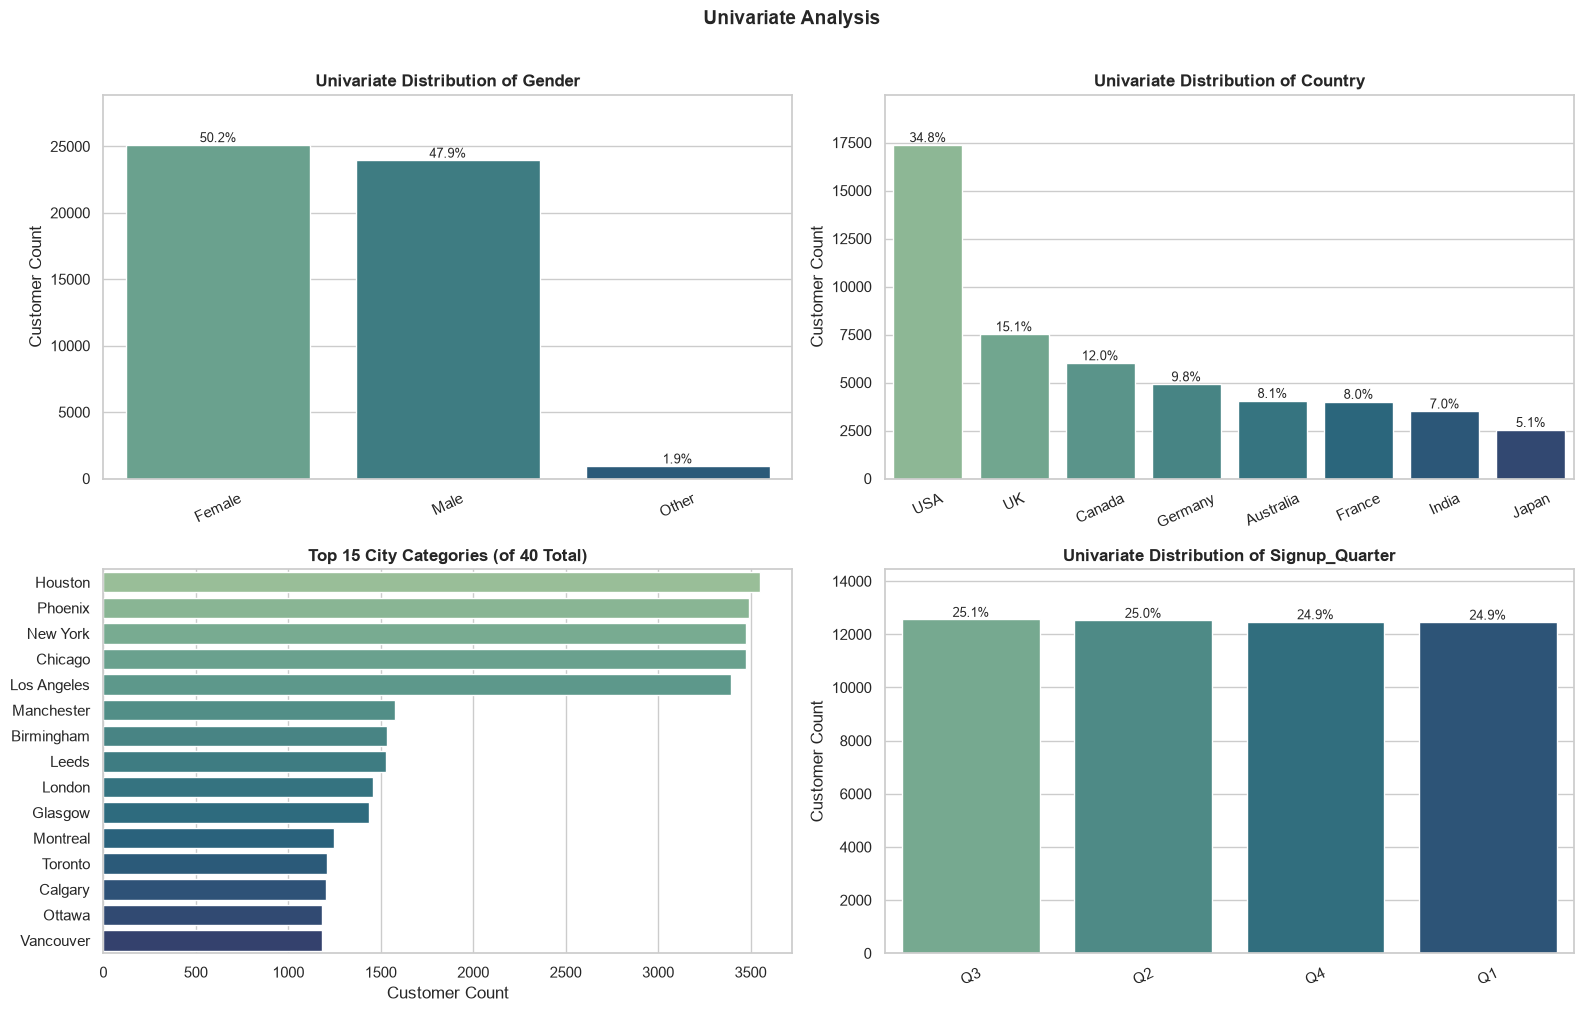

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(cat_cols[:4]):
    vc = df[col].value_counts()
    if len(vc) > 15:
        top_vc = vc.head(15)
        sns.barplot(
            x=top_vc.values,
            y=top_vc.index,
            hue=top_vc.index,
            palette="crest",
            legend=False,
            ax=axes[idx]
        )
        axes[idx].set_title(f"Top 15 {col} Categories (of {len(vc)} Total)", fontweight="bold")
        axes[idx].set_xlabel("Customer Count")
        axes[idx].set_ylabel("")
    else:
        sns.barplot(
            x=vc.index,
            y=vc.values,
            hue=vc.index,
            palette="crest",
            legend=False,
            ax=axes[idx]
        )
        for p in axes[idx].patches:
            h = int(p.get_height())
            axes[idx].annotate(
                f"{h / len(df) * 100:.1f}%",
                (p.get_x() + p.get_width() / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=9
            )
        axes[idx].set_ylim(0, vc.max() * 1.15)
        axes[idx].set_title(f"Univariate Distribution of {col}", fontweight="bold")
        axes[idx].set_xlabel("")
        axes[idx].set_ylabel("Customer Count")
        axes[idx].tick_params(axis="x", rotation=25)

plt.suptitle("Univariate Analysis", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()